In [5]:
%load_ext autoreload
%autoreload 2

import os
from torchvision import models
from torchvision import transforms
from PIL import Image
import torch
import pandas as  pd
import scipy.io as sio
import numpy as np
import glob
import natsort
from scipy.spatial.distance import cdist
from pathlib import Path
import sys
import matplotlib.pyplot as plt
import helperFuns as helper
import cv2
from sklearn.svm import LinearSVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

# The module lives one level up from this notebook; add that parent explicitly
module_parent = str(Path.cwd().parent)
if module_parent not in sys.path:
    sys.path.insert(0, module_parent)
    print('Inserted', module_parent, 'into sys.path')
else:
    print('Parent already on sys.path:', module_parent)

# Add the helper functions directory to the path
helper_functions_path = Path(module_parent) / 'helperFunctions' / 'StimulusModeling'
if str(helper_functions_path) not in sys.path:
    sys.path.insert(0, str(helper_functions_path))

import stim_transformations as stf

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Parent already on sys.path: /mnt/DataDrive3/emeyer/TreeShrewObjectRecognition


In [2]:
img_size = 10
img_type = '.png'
img_set = 'isetbio'
taskName = 'Camel_background_matrix'
projectpath = '/mnt/DataDrive3/emeyer/TreeShrewObjectRecognition/'
getDataPath = projectpath + '4_treeShrewBehavior/behaviorData/'
camel0 = 0

if taskName == 'Camel_Rhino_test_nn':
    distractor = 'rhino'
else:
    distractor = 'wrench'

img_folder = f'{projectpath}stimulusSets/isettreeshrew/treeshrew_{img_size}/{taskName}_quad/original/merged/'

/mnt/DataDrive3/emeyer/TreeShrewObjectRecognition/5_behaviorModeling/helperFuns.py:56: RuntimeWarning: Mean of empty slice
  avg_perf[tt_idx, dd_idx] = np.nanmean(


72
Loading alexnet_bn_ir_64x64_input_pool_6. Pretrained: True. Model Family: imagenet.
Loaded parameters from ../mouse_vision/model_ckpts/alexnet_bn_ir.pt
['MaxPool2d: features.3']
MaxPool2d: features.3
Loading alexnet_bn_ir_64x64_input_pool_6. Pretrained: True. Model Family: imagenet.
Loaded parameters from ../mouse_vision/model_ckpts/alexnet_bn_ir.pt
Loading alexnet_bn_ir_64x64_input_pool_6. Pretrained: True. Model Family: imagenet.
Loaded parameters from ../mouse_vision/model_ckpts/alexnet_bn_ir.pt
Loading alexnet_bn_ir_64x64_input_pool_6. Pretrained: True. Model Family: imagenet.
Loaded parameters from ../mouse_vision/model_ckpts/alexnet_bn_ir.pt
Loading alexnet_bn_ir_64x64_input_pool_6. Pretrained: True. Model Family: imagenet.
Loaded parameters from ../mouse_vision/model_ckpts/alexnet_bn_ir.pt
Loading alexnet_bn_ir_64x64_input_pool_6. Pretrained: True. Model Family: imagenet.
Loaded parameters from ../mouse_vision/model_ckpts/alexnet_bn_ir.pt
Loading alexnet_bn_ir_64x64_input_poo

/home/arcarolab_adm/anaconda3/lib/python3.11/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/home/arcarolab_adm/anaconda3/lib/python3.11/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


['MaxPool2d: features.2']
MaxPool2d: features.2


/home/arcarolab_adm/anaconda3/lib/python3.11/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=VGG16_Weights.IMAGENET1K_V1`. You can also use `weights=VGG16_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


['MaxPool2d: features.4']
MaxPool2d: features.4
MaxPool2d: features.3
MaxPool2d: features.2
MaxPool2d: features.4
Loading alexnet_bn_ir_64x64_input_pool_6. Pretrained: True. Model Family: imagenet.
Loaded parameters from ../mouse_vision/model_ckpts/alexnet_bn_ir.pt
['MaxPool2d: features.3']
MaxPool2d: features.3
Loading alexnet_bn_ir_64x64_input_pool_6. Pretrained: True. Model Family: imagenet.
Loaded parameters from ../mouse_vision/model_ckpts/alexnet_bn_ir.pt
Loading alexnet_bn_ir_64x64_input_pool_6. Pretrained: True. Model Family: imagenet.
Loaded parameters from ../mouse_vision/model_ckpts/alexnet_bn_ir.pt
Loading alexnet_bn_ir_64x64_input_pool_6. Pretrained: True. Model Family: imagenet.
Loaded parameters from ../mouse_vision/model_ckpts/alexnet_bn_ir.pt
Loading alexnet_bn_ir_64x64_input_pool_6. Pretrained: True. Model Family: imagenet.
Loaded parameters from ../mouse_vision/model_ckpts/alexnet_bn_ir.pt
Loading alexnet_bn_ir_64x64_input_pool_6. Pretrained: True. Model Family: imag

... (42 outputs left out)

/home/arcarolab_adm/anaconda3/lib/python3.11/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/home/arcarolab_adm/anaconda3/lib/python3.11/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


['MaxPool2d: features.2']
MaxPool2d: features.2


/home/arcarolab_adm/anaconda3/lib/python3.11/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=VGG16_Weights.IMAGENET1K_V1`. You can also use `weights=VGG16_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


['MaxPool2d: features.4']
MaxPool2d: features.4
MaxPool2d: features.3
MaxPool2d: features.2
MaxPool2d: features.4


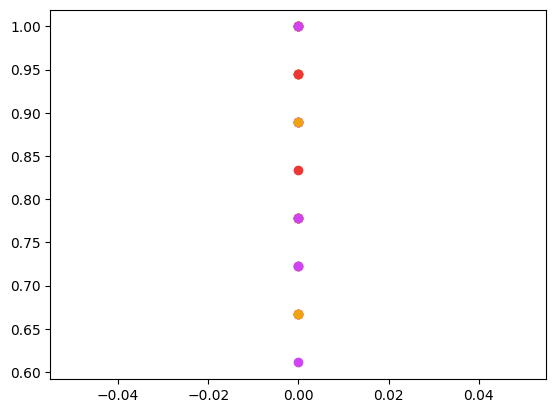

In [24]:
_, _, _, targ_idx, dist_idx = helper.get_train_targdist_data(getDataPath,taskName)
targ_idx = targ_idx.astype(int)
dist_idx = dist_idx.astype(int)

# Load and sort images using natsort
img_files = natsort.natsorted(glob.glob(f'{img_folder}*{img_type}'))
all_names = [os.path.splitext(os.path.basename(img_file))[0].split('_') for img_file in img_files]

Y_labels = [name[0] for name in all_names]
unique_labels = np.unique(Y_labels)

# Format images into DNN input format split into target and distractor sets
DNN_input_targ, DNN_input_dist = helper.structure_isetbio_data(img_files, Y_labels, unique_labels, input_size = [227,227])

firstLayMaxPerf = []  # Initialize a list to store the maximum performance of the first layer for each iteration
for i in range(10):
    # Perform 100 random train test splits of the target and distractor images using scikit-learn's train_test_split function. This will give us a more robust estimate of the model's performance.
    train_targ_idx, test_targ_idx = train_test_split(targ_idx, test_size=0.5)
    train_dist_idx, test_dist_idx = train_test_split(dist_idx, test_size=0.5)

    network = ['alexnet_mouse','alexnet','vgg16']  # 'alexnet_mouse', 'alexnet', 'vgg16'
    lay_types = ['ReLU','MaxPool2d','Linear']

    # Initialize distances variable
    # Initialize nested lists for activations
    act_train_targ = [[] for _ in range(len(network))]
    act_train_dist = [[] for _ in range(len(network))]
    act_test_targ = [[] for _ in range(len(network))]
    act_test_dist = [[] for _ in range(len(network))]
    perfCorr = [[] for _ in range(len(network))]
    distance = [dict() for _ in range(len(network))]
    all_layers = []

    for nn_idx, nn in enumerate(network):

        test_img = cv2.imread(f'{img_folder}camel_{1}.png', cv2.IMREAD_GRAYSCALE)
        _, model_layers = stf.transform_image(test_img, operation='NN', layer_types = lay_types, network=nn)
        if nn == 'alexnet_mouse':
            model_layers = ['MaxPool2d: features.3']
        elif nn == 'alexnet':
            model_layers = ['MaxPool2d: features.2']
        elif nn == 'vgg16':
            model_layers = ['MaxPool2d: features.4']
            
        print(model_layers)
        act_train_targ[nn_idx] = [[] for _ in range(len(model_layers))]
        act_train_dist[nn_idx] = [[] for _ in range(len(model_layers))]
        act_test_targ[nn_idx] = [[] for _ in range(len(model_layers))]
        act_test_dist[nn_idx] = [[] for _ in range(len(model_layers))]
        all_layers.append(model_layers)

        for lay_idx, layers in enumerate(model_layers):
            print(layers)
            for tt_idx, tt in enumerate(train_targ_idx):
                # Load the original image and convert to grayscale
                img = Image.open(f'{img_folder}camel_{tt}.png')
                img = np.array(img)

                act, _ = stf.transform_image(img, operation='NN', layer_types = layers, network=nn)
                act_train_targ[nn_idx][lay_idx].append(act[0].flatten())

            for tt_idx, tt in enumerate(test_targ_idx):
                # Load the original image and convert to grayscale
                img = Image.open(f'{img_folder}camel_{tt}.png')
                img = np.array(img)

                act, _ = stf.transform_image(img, operation='NN', layer_types = layers , network=nn)
                act_test_targ[nn_idx][lay_idx].append(act[0].flatten())
            
            for dd_idx, dd in enumerate(train_dist_idx):
                # Load the original image and convert to grayscale
                img = Image.open(f'{img_folder}{distractor}_{dd}.png')
                img = np.array(img)

                act, _ = stf.transform_image(img, operation='NN', layer_types = layers, network=nn)
                act_train_dist[nn_idx][lay_idx].append(act[0].flatten())

            for dd_idx, dd in enumerate(test_dist_idx):
                # Load the original image and convert to grayscale
                img = Image.open(f'{img_folder}{distractor}_{dd}.png')
                img = np.array(img)

                act, _ = stf.transform_image(img, operation='NN', layer_types = layers, network=nn)
                act_test_dist[nn_idx][lay_idx].append(act[0].flatten())

    # Plot the results
    colors = ["#ed3636","#f1a310","#d043f3"]

    firstLayPerf = []  # Initialize a list to store the performance of the first layer for each network
    # plt.figure(figsize=(6, 6))
    for nn_idx, nn in enumerate(network):
        # Create a dictionary with regressed distances
        perfData = []

        if nn == 'alexnet_mouse':
            model_layers = ['MaxPool2d: features.3']
        elif nn == 'alexnet':
            model_layers = ['MaxPool2d: features.2']
        elif nn == 'vgg16':
            model_layers = ['MaxPool2d: features.4']

        for lay_idx, layer in enumerate(all_layers[nn_idx]):
            if layer in model_layers:
                print(layer)
                act_train = np.array(np.concatenate((act_train_targ[nn_idx][lay_idx], act_train_dist[nn_idx][lay_idx]), axis=0))
                act_test = np.array(np.concatenate((act_test_targ[nn_idx][lay_idx], act_test_dist[nn_idx][lay_idx]), axis=0))

                y_train = np.array([0] * len(train_targ_idx) + [1] * len(train_dist_idx))
                y_test = np.array([0] * len(test_targ_idx) + [1] * len(test_dist_idx))

                clf = make_pipeline(StandardScaler(),
                            LinearSVC(random_state=0, tol=1e-5))
                clf.fit(act_train, y_train)
                y_pred = clf.predict(act_test)
                y_pred_train = clf.predict(act_train)
                # NNPerf[nn_idx][lay_idx] = np.sum(y_pred == y_test) / len(y_test)

                perfData.append(np.sum(y_pred == y_test) / len(y_test))

        firstLayPerf.append(perfData[0])  # Store the performance of the first layer for each network
        plt.plot(range(len(model_layers)), perfData, label=nn, marker='o', color=colors[nn_idx])

    firstLayMaxPerf.append(max(firstLayPerf))

    # save perfData values in table with labels for each network
# import pandas as pd
# print(network)
# print(firstLayPerf)
# perf_df = pd.DataFrame({network[0]: firstLayPerf[0], network[1]: firstLayPerf[1], network[2]: firstLayPerf[2]}, index=[0])
# perf_df.to_csv(f'{projectpath}5_behaviorModeling/distData/{taskName}/NNFirstLayerPerf_{i}.csv', index=False)
